# HPC compression study — local analysis

Copy the bundle from Dante, then set `BUNDLE` below. This notebook reads JSON and histories only: no training, dataset access, checkpoint loading, or test evaluation. HPC absolute paths in the saved state are treated as provenance.

Only completed runs enter comparisons. Error bars show sample standard deviation across seeds, **not confidence intervals**. Missing or capped runs are displayed separately. The 0.05 decision comes from the saved validation selection. With a fixed eight-qubit circuit, the curves measure representation size and circuit application count, not scaling in qubit count.

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path.cwd().parent
BUNDLE = Path(os.environ.get("QMLA_RESULTS_DIR", PROJECT / "results" / "compression_sweep")).expanduser()
ROOT = BUNDLE / "study" if (BUNDLE / "study" / "study.json").exists() else BUNDLE
assert (ROOT / "study.json").exists(), f"Set BUNDLE to the copied results directory: {ROOT}"


In [2]:
state = json.loads((ROOT / "study.json").read_text(encoding="utf-8"))
seeds = state["configuration"]["experiment"]["training"]["seeds"]
levels = state["configuration"]["levels"]
selection = state.get("selection")
rows = []
for job in state["jobs"].values():
    row = {k: v for k, v in job.items() if k != "attempts"}
    attempts = job.get("attempts", [])
    for field in ("peak_process_rss_bytes", "peak_gpu_allocated_bytes", "peak_gpu_reserved_bytes"):
        row[field] = max((a.get(field, 0) for a in attempts), default=0)
    rows.append(row)
columns = ["key", "level", "variant", "seed", "status", "stopping_reason", "feature_values",
           "compression_axis", "macro_f1", "elapsed_seconds", "time_to_best_seconds",
           "peak_process_rss_bytes", "peak_gpu_allocated_bytes", "peak_gpu_reserved_bytes"]
runs = pd.DataFrame(rows).reindex(columns=columns)
complete = runs.loc[runs.status.eq("completed")].copy()
print(f"Study: {state['id']} | expected seeds: {seeds}")
print(f"Study runtime: {state['elapsed_seconds']/3600:.2f} h | preparation: {state['preparation_seconds']/60:.1f} min")
print("Last stop:", state.get("last_stop"), "| expansion stop:", state.get("expansion_stopped"))
display(runs.groupby(["variant", "status"]).size().rename("runs").to_frame())
display(runs.loc[~runs.status.eq("completed"), ["key", "status", "stopping_reason", "elapsed_seconds"]])

Study: compression_a273a0297ce0 | expected seeds: [42, 1324, 987654]
Study runtime: 146.52 h | preparation: 0.6 min
Last stop: None | expansion stop: None


runs
variant               status           
compression_cnn       completed      24
compression_patch_cnn completed      10
compression_qufex     completed      10
                      interrupted     1
direct_cnn            completed       3

,key,status,stopping_reason,elapsed_seconds
41,M2_compression_qufex_seed1324,interrupted,SIGUSR1,15242.042178


In [3]:
runs.columns

Index(['key', 'level', 'variant', 'seed', 'status', 'stopping_reason',
       'feature_values', 'compression_axis', 'macro_f1', 'elapsed_seconds',
       'time_to_best_seconds', 'peak_process_rss_bytes',
       'peak_gpu_allocated_bytes', 'peak_gpu_reserved_bytes'],
      dtype='str')

## Bottleneck configurations

These tables use the saved study configuration, so an older M-only study keeps its original schedule. A bottleneck row describes the representation **after channel projection and adaptive average pooling**, immediately before `z + extractor(z)`. The direct CNN reference goes straight from the encoder to global pooling.

The full CNN mixes all channels and spatial neighbors. The patch CNN and QuFeX share one extractor across independent adjacent-channel, nonoverlapping 2×2 patches. The patch CNN's 3×3 convolution uses one pixel of zero padding to preserve each 2×2 patch.

In [4]:
experiment = state["configuration"].get("experiment", {})
direct = experiment.get("architectures", {}).get("direct", {})
encoder_channels = direct.get("encoder_channels", [])
pooling = direct.get("pooling", "max")
pool_size = direct.get("pool_size", 2)
image_size = experiment.get("data", {}).get("image_size")
quantum_config = experiment.get("quantum", {})
chunk_size = state["configuration"].get("sweep", {}).get("circuit_chunk_size", 256)

extractor_configurations = pd.DataFrame([
    dict(model="compression_cnn", operations="Conv3×3 C→C (padding=1) → ReLU → Conv1×1 C→C",
         scope="Whole compressed map", residual="z + extractor(z)"),
    dict(model="compression_patch_cnn", operations="Conv3×3 2→8 (padding=1) → ReLU → Conv1×1 8→2",
         scope="Shared independently across 2×2×2 patches", residual="z + extractor(z)"),
    dict(model="compression_qufex", operations="8 inputs → 8-qubit, 1-filter circuit → 8 measurements → 2×2×2 patch",
         scope="Shared independently across 2×2×2 patches", residual="z + extractor(z)"),
    dict(model="direct_cnn", operations="Encoder → global average pooling → classifier",
         scope="No bottleneck extraction module", residual="None"),
])
display(extractor_configurations)

# Include configured variants even before they have finished training.
saved_shapes = dict(levels)
for job in state["jobs"].values():
    if job["variant"] != "direct_cnn" and job["level"] not in saved_shapes:
        saved_shapes[job["level"]] = dict(channels=job.get("channels"),
                                         spatial_size=job.get("spatial_size"))
bottleneck_rows = []
for level_name, spec in [*saved_shapes.items(), ("reference", None)]:
    is_reference = spec is None
    channels = encoder_channels[-1] if is_reference and encoder_channels else (spec or {}).get("channels")
    pool_blocks = (spec or {}).get("pool_blocks", -1)
    if pool_blocks == -1:
        pool_blocks = direct.get("pool_blocks", -1)
    if pool_blocks == -1:
        pool_blocks = len(encoder_channels) if encoder_channels else None
    if pooling == "none":
        pool_blocks = 0
    encoder_size = image_size // pool_size**pool_blocks if image_size is not None and pool_blocks is not None else None
    spatial_size = encoder_size if is_reference else spec.get("spatial_size")
    shape = f"{channels}×{spatial_size}×{spatial_size}" if channels and spatial_size else "Unavailable"
    encoder_shape = f"{encoder_channels[-1]}×{encoder_size}×{encoder_size}" if encoder_channels and encoder_size else "Unavailable"
    projection = "None"
    if not is_reference:
        if not channels or not encoder_channels:
            projection = "Unavailable"
        elif direct.get("projection", "auto") == "conv" or channels != encoder_channels[-1]:
            projection = f"1×1 conv {encoder_channels[-1]}→{channels}"
    variants = ("direct_cnn",) if is_reference else ("compression_cnn", "compression_patch_cnn", "compression_qufex")
    for variant in variants:
        matching = [job for job in state["jobs"].values()
                    if job["variant"] == variant and (is_reference or job["level"] == level_name)]
        values = channels * spatial_size**2 if channels and spatial_size else next(
            (job.get("feature_values") for job in matching), None)
        is_quantum = variant == "compression_qufex"
        extractor_parameters = (4 if is_quantum else 170 if variant == "compression_patch_cnn"
                                else 10 * channels**2 + 2 * channels if variant == "compression_cnn" and channels
                                else 0 if is_reference else None)
        bottleneck_rows.append(dict(
            level=level_name, model=variant, encoder_shape=encoder_shape,
            encoder_pool_blocks=pool_blocks, channel_projection=projection,
            bottleneck_shape=shape if not is_reference else "None (encoder → GAP)",
            adaptive_pool=spatial_size if not is_reference else "None",
            feature_values=values, extractor_parameters=extractor_parameters,
            qubits=quantum_config.get("qubits", 8) if is_quantum else 0,
            filters=quantum_config.get("filters", 1) if is_quantum else 0,
            circuit_instances_per_image=values // 8 if is_quantum and values else 0 if not is_quantum else None,
            circuit_chunk_size=chunk_size if is_quantum else None,
            completed_seeds=f"{sum(job['status'] == 'completed' for job in matching)}/{len(seeds)}",
        ))
bottleneck_configurations = pd.DataFrame(bottleneck_rows)
display(bottleneck_configurations)
print("Extractor parameters exclude the encoder, projection and classifier.")
print("Quantum circuit instances count patch applications per image; chunk size limits one batched call.")


,model,operations,scope,residual
0,compression_cnn,Conv3×3 C→C (padding=1) → ReLU → Conv1×1 C→C,Whole compressed map,z + extractor(z)
1,compression_patch_cnn,Conv3×3 2→8 (padding=1) → ReLU → Conv1×1 8→2,Shared independently across 2×2×2 patches,z + extractor(z)
2,compression_qufex,"8 inputs → 8-qubit, 1-filter circuit → 8 measu...",Shared independently across 2×2×2 patches,z + extractor(z)
3,direct_cnn,Encoder → global average pooling → classifier,No bottleneck extraction module,None


,level,model,encoder_shape,encoder_pool_blocks,channel_projection,bottleneck_shape,adaptive_pool,feature_values,extractor_parameters,qubits,filters,circuit_instances_per_image,circuit_chunk_size,completed_seeds
0,K1,compression_cnn,64×32×32,1,None,64×32×32,32,65536,41088,0,0,0,NaN,3/3
1,K1,compression_patch_cnn,64×32×32,1,None,64×32×32,32,65536,170,0,0,0,NaN,0/3
2,K1,compression_qufex,64×32×32,1,None,64×32×32,32,65536,4,8,1,8192,256.0,0/3
3,K0,compression_cnn,64×16×16,2,None,64×16×16,16,16384,41088,0,0,0,NaN,3/3
4,K0,compression_patch_cnn,64×16×16,2,None,64×16×16,16,16384,170,0,0,0,NaN,0/3
5,K0,compression_qufex,64×16×16,2,None,64×16×16,16,16384,4,8,1,2048,256.0,0/3
6,M0,compression_cnn,64×8×8,3,None,64×8×8,8,4096,41088,0,0,0,NaN,3/3
7,M0,compression_patch_cnn,64×8×8,3,None,64×8×8,8,4096,170,0,0,0,NaN,0/3
8,M0,compression_qufex,64×8×8,3,None,64×8×8,8,4096,4,8,1,512,256.0,0/3
9,M1,compression_cnn,64×8×8,3,None,64×6×6,6,2304,41088,0,0,0,NaN,3/3


Extractor parameters exclude the encoder, projection and classifier.
Quantum circuit instances count patch applications per image; chunk size limits one batched call.


## Validation selection and compression curve

K1/K0 retain larger spatial maps by reducing encoder pooling; M0–M3 vary spatial resolution after the original encoder, and M4–M5 also reduce channels. The direct CNN is an additional reference. A mean degradation of exactly 0.05 relative to the saved reference level is acceptable. The notebook does not make a new selection or replace incomplete seeds.

In [5]:
if selection:
    print("Saved selected level:", selection["selected_level"])
    display(pd.DataFrame(selection["decisions"]))
else:
    print("No selection yet: all configured classical level/seed runs must complete.")

summary = complete.groupby(["level", "variant", "feature_values", "compression_axis"], dropna=False).agg(
    macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
    seeds_completed=("seed", "nunique"), runtime_seconds=("elapsed_seconds", "mean"),
    gpu_gib=("peak_gpu_allocated_bytes", lambda s: s.mean() / 2**30),
    rss_gib=("peak_process_rss_bytes", lambda s: s.mean() / 2**30),
).reset_index()
display(summary)
full = summary.loc[summary.seeds_completed.eq(len(seeds))]


Saved selected level: M5


,level,scores,mean_macro_f1,mean_drop,drop_std,acceptable
0,K1,"[0.8133550866496114, 0.8043683754802581, 0.798...",0.805351,0.000000,0.000000,True
1,K0,"[0.7947401077400679, 0.8022101270849357, 0.798...",0.798561,0.006790,0.010321,True
2,M0,"[0.7977301139767858, 0.7996850862439007, 0.810...",0.802524,0.002826,0.013821,True
3,M1,"[0.7927994551266889, 0.7975462219227417, 0.790...",0.793729,0.011622,0.007744,True
4,M2,"[0.804747095335823, 0.8035403468999905, 0.8011...",0.803138,0.002213,0.005828,True
5,M3,"[0.8050009639845624, 0.8056893728054725, 0.806...",0.805812,-0.000462,0.008419,True
6,M4,"[0.7962696537283342, 0.8114122580674947, 0.789...",0.798909,0.006441,0.012313,True
7,M5,"[0.7977193870430016, 0.8010152002580563, 0.796...",0.798362,0.006988,0.007520,True


,level,variant,feature_values,compression_axis,macro_f1_mean,macro_f1_std,seeds_completed,runtime_seconds,gpu_gib,rss_gib
0,K0,compression_cnn,16384,spatial,0.798561,0.003738,3,9073.071421,0.047558,2.546853
1,K1,compression_cnn,65536,spatial,0.805351,0.007561,3,10061.812629,0.074963,2.536568
2,M0,compression_cnn,4096,spatial,0.802524,0.006683,3,3810.184639,0.030438,2.447622
3,M1,compression_cnn,2304,spatial,0.793729,0.003448,3,3513.101170,0.030128,2.442445
4,M2,compression_cnn,1024,spatial,0.803138,0.001844,3,4629.742325,0.030102,2.444534
5,M2,compression_patch_cnn,1024,spatial,0.808213,NaN,1,12121.041963,0.063908,2.887672
6,M2,compression_qufex,1024,spatial,0.790619,NaN,1,49945.539206,0.122323,2.610600
7,M3,compression_cnn,256,spatial,0.805812,0.000879,3,6488.069218,0.030087,2.450488
8,M3,compression_patch_cnn,256,spatial,0.796467,0.005530,3,8721.233741,0.025936,2.687904
9,M3,compression_qufex,256,spatial,0.796697,0.007635,3,27143.406864,0.049541,2.638341


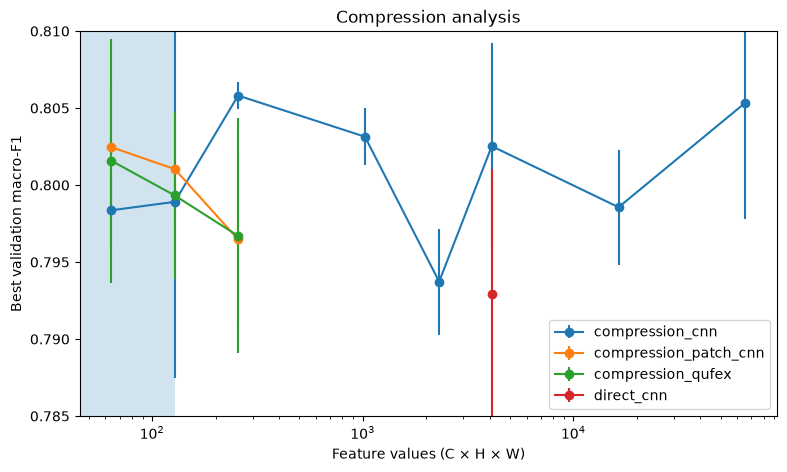

In [6]:

fig, ax = plt.subplots(figsize=(9, 5))

channel_rows = full[full.level.eq("M4")]
channels_compression = channel_rows.iloc[0].feature_values if not channel_rows.empty else None
if channels_compression is not None:
    ax.fill_betweenx([0, 1], 0, channels_compression, alpha=0.2)

for variant, group in full.groupby("variant"):
    group = group.sort_values("feature_values")
    ax.errorbar(group.feature_values, group.macro_f1_mean,
                yerr=group.macro_f1_std.fillna(0), marker="o", label=variant)
    # for row in group.itertuples():
    #     if row.compression_axis == "channel":
    #         ax.annotate(row.level + " (channels)", (row.feature_values, row.macro_f1_mean),
    #                     xytext=(4, 6), textcoords="offset points", fontsize=8)
# if selection:
#     floor = np.mean(selection["reference_scores"]) - selection["threshold"]
#     ax.axhline(floor, color="gray", linestyle="--", label="M0 − 0.05 acceptance floor")
ax.set(xlabel="Feature values (C × H × W)", ylabel="Best validation macro-F1",
       title="Compression analysis")
if channels_compression is not None:
    ax.annotate("Channel compression", (channels_compression - 100, 0.789), fontsize=8)
ax.set_ylim(0.785, 0.810)
ax.set_xscale("log")

if ax.get_legend_handles_labels()[0]:
    ax.legend()
plt.show()

## Paired quantum–classical differences

Pair by level and seed; positive values favor QuFeX. Full CNN and patch CNN answer different control questions. Partial pairs remain visible in the table, but the plot requires all configured seeds.

,level,seed,control,feature_values,delta
0,M5,42,compression_cnn,64,-0.005277
1,M5,1324,compression_cnn,64,0.005694
2,M5,987654,compression_cnn,64,0.009235
3,M4,42,compression_cnn,128,0.003476
4,M4,1324,compression_cnn,128,-0.006900
5,M4,987654,compression_cnn,128,0.004667
6,M3,42,compression_cnn,256,-0.000235
7,M3,1324,compression_cnn,256,-0.009950
8,M3,987654,compression_cnn,256,-0.017160
9,M2,42,compression_cnn,1024,-0.014128


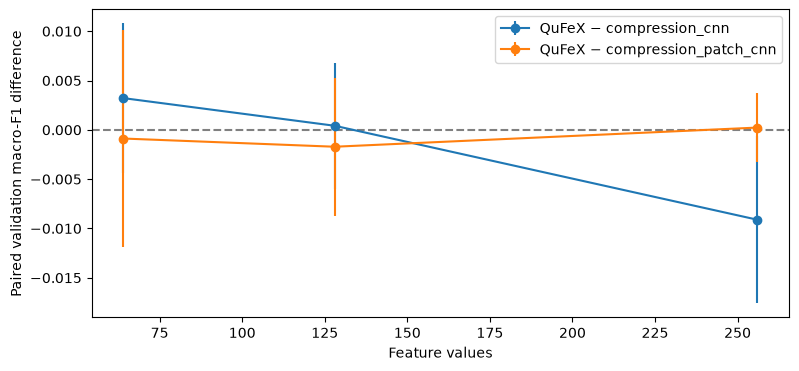

In [7]:
pair_rows = []
quantum = complete.loc[complete.variant.eq("compression_qufex")]
for control in ("compression_cnn", "compression_patch_cnn"):
    classical = complete.loc[complete.variant.eq(control)]
    pairs = quantum.merge(classical, on=["level", "seed"], suffixes=("_q", "_c"),
                          validate="one_to_one")
    for row in pairs.itertuples():
        pair_rows.append(dict(level=row.level, seed=row.seed, control=control,
                              feature_values=row.feature_values_q,
                              delta=row.macro_f1_q - row.macro_f1_c))
pairs = pd.DataFrame(pair_rows, columns=["level", "seed", "control", "feature_values", "delta"])
display(pairs)
paired_summary = pairs.groupby(["level", "control", "feature_values"]).agg(
    mean=("delta", "mean"), std=("delta", "std"), count=("seed", "nunique")).reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
for control, group in paired_summary.loc[paired_summary["count"].eq(len(seeds))].groupby("control"):
    group = group.sort_values("feature_values")
    ax.errorbar(group.feature_values, group["mean"], yerr=group["std"].fillna(0),
                marker="o", label=f"QuFeX − {control}")
ax.axhline(0, color="gray", linestyle="--")
ax.set(xlabel="Feature values", ylabel="Paired validation macro-F1 difference")
if ax.get_legend_handles_labels()[0]:
    ax.legend()
plt.show()

## Cost and learning histories

Runtime includes attempted work on interrupted epochs. GPU allocation and process RSS are measured separately; a circuit chunk size does not bound the complete autograd graph. Profiling estimates are estimates of training steps, not evidence of convergence.

,level,status,elapsed_seconds,stopping_reason,step_seconds_mean,step_seconds_std,warmup_steps,measured_steps,estimated_training_epoch_seconds,estimated_max_training_seconds,estimate_scope,runtime
0,M5,completed,6.436449,None,0.051977,0.007876,5,20,398.145803,19907.290131,training steps only; excludes validation/check...,{'process_started_at_utc': '2026-09-26T08:20:1...
1,M4,completed,6.164882,None,0.055874,0.010809,5,20,427.996467,21399.823372,training steps only; excludes validation/check...,{'process_started_at_utc': '2026-09-28T10:22:1...
2,M3,completed,5.035786,None,0.067319,0.001998,5,20,515.665983,25783.299169,training steps only; excludes validation/check...,{'process_started_at_utc': '2026-09-28T10:22:1...
3,M2,completed,8.260925,None,0.191351,0.012564,5,20,1465.748029,73287.401445,training steps only; excludes validation/check...,{'process_started_at_utc': '2026-10-01T07:56:0...


,key,status,elapsed_seconds,time_to_best_seconds,peak_process_rss_bytes,peak_gpu_allocated_bytes
0,M0_compression_cnn_seed42,completed,2571.325083,1724.741553,2627284992,47354880
1,M0_compression_cnn_seed1324,completed,3370.816296,2508.312338,2626166784,25347072
2,M0_compression_cnn_seed987654,completed,5488.412537,5266.223224,2630889472,25347072
3,M1_compression_cnn_seed42,completed,3664.854695,2755.774671,2622205952,47240192
4,M1_compression_cnn_seed1324,completed,4095.700944,3163.438426,2622205952,24904192
5,M1_compression_cnn_seed987654,completed,2778.747871,1813.424030,2623254528,24904192
6,M2_compression_cnn_seed42,completed,5321.321931,4337.634436,2624544768,47158272
7,M2_compression_cnn_seed1324,completed,4319.844018,3288.400568,2624921600,24904192
8,M2_compression_cnn_seed987654,completed,4248.061026,3222.550868,2624929792,24904192
9,M3_compression_cnn_seed42,completed,6514.036884,6250.829291,2630909952,47109120


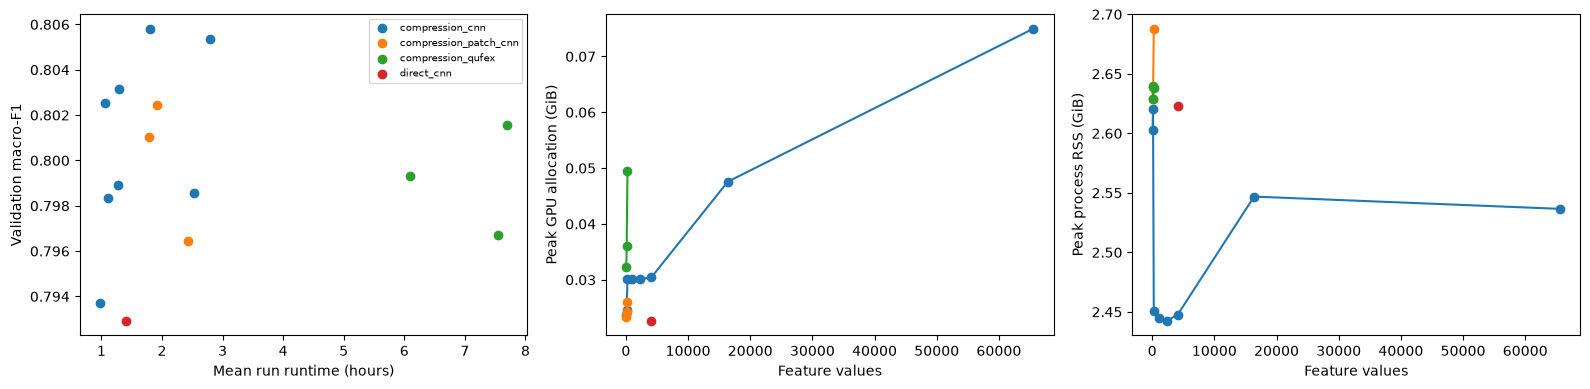

M0_compression_cnn_seed42


,epoch,train_loss,validation_loss,learning_rate,next_learning_rate,epoch_seconds,accuracy,macro_precision,macro_recall,balanced_accuracy,macro_f1,weighted_f1,cumulative_elapsed_seconds
0,0,0.867173,0.790647,0.001,0.001,121.151027,0.625695,0.589973,0.632143,0.632143,0.565061,0.609627,126.043393
1,1,0.719224,0.688769,0.001,0.001,106.573153,0.703221,0.670798,0.699266,0.699266,0.665587,0.701155,232.670100
2,2,0.668259,0.712779,0.001,0.001,106.392077,0.691646,0.660050,0.697532,0.697532,0.667300,0.694924,339.113377
3,3,0.637134,0.609478,0.001,0.001,106.901087,0.769096,0.753208,0.740604,0.740604,0.746265,0.768855,446.067542
4,4,0.610698,0.611929,0.001,0.001,106.802032,0.751580,0.719755,0.746216,0.746216,0.726860,0.750410,552.918162
5,5,0.592953,0.562536,0.001,0.001,107.405336,0.785317,0.765690,0.763954,0.763954,0.761572,0.780589,660.358343
6,6,0.578817,0.584742,0.001,0.001,106.651662,0.790724,0.793427,0.750808,0.750808,0.765499,0.783434,767.067504
7,7,0.570758,0.541437,0.001,0.001,106.675313,0.801767,0.796394,0.772208,0.772208,0.780566,0.796387,873.801508
8,8,0.564526,0.560342,0.001,0.001,105.598902,0.795522,0.797677,0.760069,0.760069,0.770878,0.786958,979.456479
9,9,0.555183,0.543640,0.001,0.001,106.741899,0.800853,0.811303,0.763378,0.763378,0.781837,0.798522,1086.232946


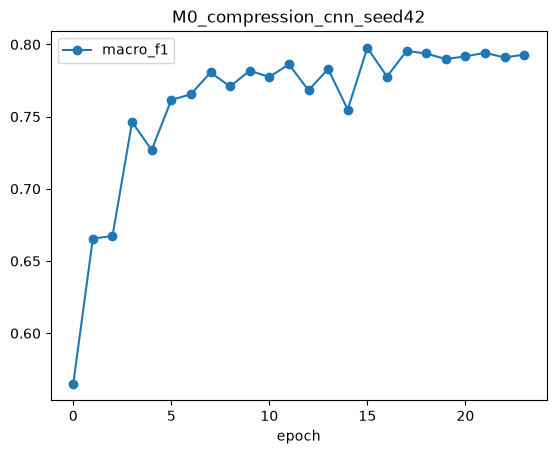

In [8]:
display(pd.DataFrame(state.get("profiles", {}).values()))
display(runs[["key", "status", "elapsed_seconds", "time_to_best_seconds",
              "peak_process_rss_bytes", "peak_gpu_allocated_bytes"]])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for variant, group in full.groupby("variant"):
    axes[0].scatter(group.runtime_seconds / 3600, group.macro_f1_mean, label=variant)
    group = group.sort_values("feature_values")
    axes[1].plot(group.feature_values, group.gpu_gib, marker="o", label=variant)
    axes[2].plot(group.feature_values, group.rss_gib, marker="o", label=variant)
axes[0].set(xlabel="Mean run runtime (hours)", ylabel="Validation macro-F1")
axes[1].set(xlabel="Feature values", ylabel="Peak GPU allocation (GiB)")
axes[2].set(xlabel="Feature values", ylabel="Peak process RSS (GiB)")
if axes[0].get_legend_handles_labels()[0]:
    axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Select any run key from the table; paths are rebuilt relative to the copied bundle.
RUN_KEY = next(iter(state["jobs"]), None)
if RUN_KEY:
    history_path = ROOT / "jobs" / f"{state['id']}_{RUN_KEY}" / "history.json"
    if history_path.exists():
        history = pd.read_json(history_path)
        print(RUN_KEY)
        display(history)
        if "macro_f1" in history:
            history.plot(x="epoch", y="macro_f1", marker="o", title=RUN_KEY)
            plt.show()

## Frozen test results (if explicitly evaluated on the HPC)

This cell only reads results already saved by the explicit `evaluate` stage. It never evaluates or selects checkpoints. Test scores must not be used to revise the compression threshold or expansion order.

In [ ]:
manifest = state.get("evaluation_manifest") or []
allowed = {item["key"] for item in manifest}
test_rows = []
for key, result in state.get("evaluations", {}).items():
    if key in allowed and result["status"] == "completed":
        test_rows.append({"key": key, **result["metrics"]})
if test_rows:
    display(pd.json_normalize(test_rows))
else:
    print("No completed frozen test evaluations in this bundle.")
print("Frozen checkpoints:", len(manifest), "| completed test evaluations:", len(test_rows))

No completed frozen test evaluations in this bundle.
Frozen checkpoints: 0 | completed test evaluations: 0
